In [1]:
import os
import torch
import pandas as pd
import scanpy as sc
from sklearn import metrics
import multiprocessing as mp
from STWaveGraph.STWaveGraph import STWaveGraph
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

import matplotlib.pyplot as plt
import seaborn as sns

import os,sys
from pathlib import Path
from tqdm import tqdm
import warnings

In [2]:
device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
import rpy2

In [ ]:
import h5py
import pandas as pd
import anndata as ad
import numpy as np

file_path = '/root/workspace/STWaveGraph-main copy/Data/osmFISHresult/osmFISH_cortex.h5'

with h5py.File(file_path, 'r') as f:
    print("🔍 正在解析自定义 H5 文件...")
    X_data = f['X'][:]
    genes = [g.decode('utf-8') if isinstance(g, bytes) else str(g) for g in f['Genes'][:]]
    obs_dict = {}
    if 'Region' in f.keys():
        obs_dict['Region'] = [r.decode('utf-8') if isinstance(r, bytes) else str(r) for r in f['Region'][:]]
    if 'Y' in f.keys():
        obs_dict['Y_label'] = [y.decode('utf-8') if isinstance(y, bytes) else str(y) for y in f['Y'][:]]
        
    obs_df = pd.DataFrame(obs_dict)
    obs_df.index = [f"cell_{i}" for i in range(X_data.shape[0])] 
    
    var_df = pd.DataFrame(index=genes)

    adata = ad.AnnData(X=X_data, obs=obs_df, var=var_df)
 
    if 'Pos' in f.keys():
        adata.obsm['spatial'] = f['Pos'][:]
adata.var_names_make_unique()
adata.obs_names_make_unique()

print("\n✅ 成功手工组装 AnnData 数据对象！数据结构如下：")
print(adata)

🔍 正在解析自定义 H5 文件...

✅ 成功手工组装 AnnData 数据对象！数据结构如下：
AnnData object with n_obs × n_vars = 4839 × 33
    obs: 'Region', 'Y_label'
    obsm: 'spatial'


/tmp/ipykernel_3908984/2297526194.py:31: FutureWarning: X.dtype being converted to np.float32 from int32. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  adata = ad.AnnData(X=X_data, obs=obs_df, var=var_df)


In [4]:
import torch
print("PyTorch版本:", torch.__version__)
print("CUDA是否可用:", torch.cuda.is_available())

PyTorch版本: 2.4.1+cu124
CUDA是否可用: True


<!-- 73:600:3500:random seed: 6497
6382:0.671
76:seed: 5549:0.603
510:seed: 8951:0.516 -->

In [ ]:
model = STWaveGraph(   
            adata=adata,  
            n_clusters=11,
            random_seed=991,   
            device=device,

            n_top_genes=3200,
            pca_dim=45,
            n_neighbors_spatial=8,
            expr_power=1.25,

            pretrain_epochs=320,
            finetune_epochs=200,

            lambda_rec=0.3,
            lambda_ssl=0.5,
            lambda_smooth=0.06,
            lambda_kl=1.00,
            lambda_q_cons=0.30,
            lambda_balance=0.06,
            lambda_boundary=0.18,

            refine_iters=18
        )
adata = model.train(verbose=True)

========== Stage 1: Representation Pretraining ==========


100%|██████████| 320/320 [00:27<00:00, 11.60it/s]


========== Initialize Cluster Centers ==========
========== Stage 2: Clustering Finetuning ==========


 26%|██▌       | 51/200 [00:04<00:12, 11.81it/s]

[Finetune] Epoch 50/200 | loss=0.3406 | rec=0.4047 | ssl=0.1715 | smooth=0.1452 | kl=0.0539 | balance=0.0018 | bd=0.3919 | extra_reg_on=1


...

[Finetune] Epoch 100/200 | loss=0.3189 | rec=0.3696 | ssl=0.1400 | smooth=0.1909 | kl=0.0655 | balance=0.0014 | bd=0.3373 | extra_reg_on=1


 76%|███████▌  | 151/200 [00:13<00:04, 11.70it/s]

[Finetune] Epoch 150/200 | loss=0.3045 | rec=0.3465 | ssl=0.1122 | smooth=0.2149 | kl=0.0750 | balance=0.0013 | bd=0.3126 | extra_reg_on=1


100%|██████████| 200/200 [00:17<00:00, 11.49it/s]


[Finetune] Epoch 200/200 | loss=0.3017 | rec=0.3287 | ssl=0.1027 | smooth=0.2180 | kl=0.0827 | balance=0.0019 | bd=0.3082 | extra_reg_on=1
INFO: Using external clustering ('mclust') on embedding (h) for prediction.
fitting ...
  |======================================================================| 100%


In [8]:
# # add ground_truth
# df_meta = pd.read_csv(file_fold + '/metadata.tsv', sep='\t')
# df_meta_layer = df_meta['layer_guess']
# adata.obs['ground_truth'] = df_meta_layer.values

In [9]:
adata

AnnData object with n_obs × n_vars = 4839 × 33
    obs: 'Region', 'Y_label', 'pred_domain_raw', 'pred_domain'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'log1p', 'use_q_for_pred', 'cluster_method_used', 'cluster_pca_dim', 'mclust_model', 'regularization_warmup_epochs'
    obsm: 'spatial', 'emb', 'model_q', 'soft_assign'

In [10]:
adata.obsm['emb']

array([[ 0.0100312 , -0.03732068, -0.03764893, ...,  0.06320397,
        -0.07455553,  0.2369144 ],
       [ 0.01787209,  0.14712843,  0.13864107, ...,  0.15823586,
         0.08526096,  0.04315118],
       [ 0.07441475, -0.23373707, -0.12372604, ..., -0.09846617,
        -0.09830092,  0.02122278],
       ...,
       [ 0.19712143,  0.17844667,  0.11339302, ...,  0.19756329,
         0.15712342, -0.03998864],
       [ 0.06409978,  0.0359193 , -0.06130772, ...,  0.03243911,
         0.0395727 ,  0.22474469],
       [-0.08292057, -0.04793611, -0.0888558 , ..., -0.00738565,
         0.15525797,  0.23873566]], dtype=float32)

In [12]:
adata

AnnData object with n_obs × n_vars = 4839 × 33
    obs: 'Region', 'Y_label', 'pred_domain_raw', 'pred_domain'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'log1p', 'use_q_for_pred', 'cluster_method_used', 'cluster_pca_dim', 'mclust_model', 'regularization_warmup_epochs', 'pred_domain_colors'
    obsm: 'spatial', 'emb', 'model_q', 'soft_assign'

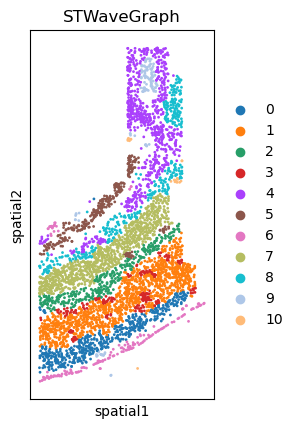

In [14]:
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["pred_domain"],
    title=["STWaveGraph"],
    spot_size=400,
    show=True
)


In [15]:
from sklearn import metrics
import pandas as pd

# ==========================================
# 1. 指定你的真实标签列名和预测结果列名
# ==========================================
# 根据你的 adata.obs，真实标签可能叫 'Region' 或 'ClusterName'
GT_COL = 'Region'          # 如果真实标签是另外一个，请改成 'ClusterName' 或者 'ClusterID'
PRED_COL = 'pred_domain'   # 你的预测结果所在的列

print(f"正在用真实的 '{GT_COL}' 和预测的 '{PRED_COL}' 计算 ARI ...")

# ==========================================
# 2. 提取数据并过滤缺失值 (NaN)
# ==========================================
# 为了防止有些细胞没有人工标注导致报错，我们提取两列并去掉没有标注的细胞
df_eval = adata.obs[[GT_COL, PRED_COL]].copy()
df_eval = df_eval.dropna()

if len(df_eval) == 0:
    print(f"❌ 错误: '{GT_COL}' 列全是空的，请检查列名是否拼写错误。")
else:
    # ==========================================
    # 3. 计算 ARI
    # ==========================================uzon
    # 强制转换为字符串类型以确保 isinstance(str) 计算稳定
    ari_score = metrics.adjusted_rand_score(
        df_eval[GT_COL].astype(str), 
        df_eval[PRED_COL].astype(str)
    )
    
    # 存入 adata 方便后续查阅
    adata.uns['ARI'] = ari_score
    
    print("-" * 40)
    print(f"✅ 有效细胞/点数量: {len(df_eval)} / {adata.n_obs}")
    print(f"🏆 计算完成，ARI 分数: {ari_score:.4f}")
    print("-" * 40)

正在用真实的 'Region' 和预测的 'pred_domain' 计算 ARI ...
----------------------------------------
✅ 有效细胞/点数量: 4839 / 4839
🏆 计算完成，ARI 分数: 0.6294
----------------------------------------


In [ ]:
from sklearn import metrics
import pandas as pd

GT_COL = 'Region'          
PRED_COL = 'pred_domain'   

print(f"正在用真实的 '{GT_COL}' 和预测的 '{PRED_COL}' 计算 ARI 和 NMI ...")

df_eval = adata.obs[[GT_COL, PRED_COL]].copy()
df_eval = df_eval.dropna()

if len(df_eval) == 0:
    print(f"❌ 错误: '{GT_COL}' 列全是空的，请检查列名是否拼写错误。")
else:
    y_true = df_eval[GT_COL].astype(str)
    y_pred = df_eval[PRED_COL].astype(str)

    ari_score = metrics.adjusted_rand_score(y_true, y_pred)
    nmi_score = metrics.normalized_mutual_info_score(y_true, y_pred)
    adata.uns['ARI'] = ari_score
    adata.uns['NMI'] = nmi_score
    
    print("-" * 40)
    print(f"✅ 有效细胞/点数量: {len(df_eval)} / {adata.n_obs}")
    print(f"🏆 ARI 分数: {ari_score:.4f}")
    print(f"🏆 NMI 分数: {nmi_score:.4f}")
    print("-" * 40)

正在用真实的 'Region' 和预测的 'pred_domain' 计算 ARI 和 NMI ...
----------------------------------------
✅ 有效细胞/点数量: 4839 / 4839
🏆 ARI 分数: 0.6294
🏆 NMI 分数: 0.7076
----------------------------------------


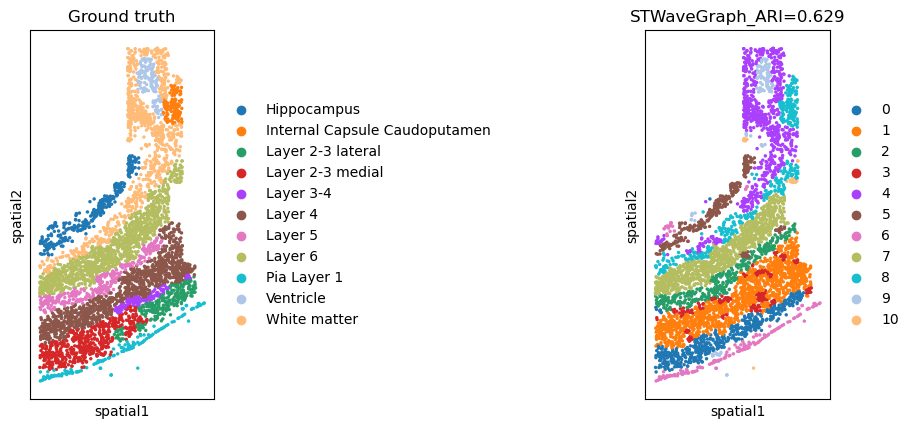

In [17]:
ARI=adata.uns['ARI']
NMI=adata.uns['NMI']
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["Region", "pred_domain"],
    title=["Ground truth", f"STWaveGraph_ARI={ARI:.3f}"],
    spot_size=500,
    show=True
)


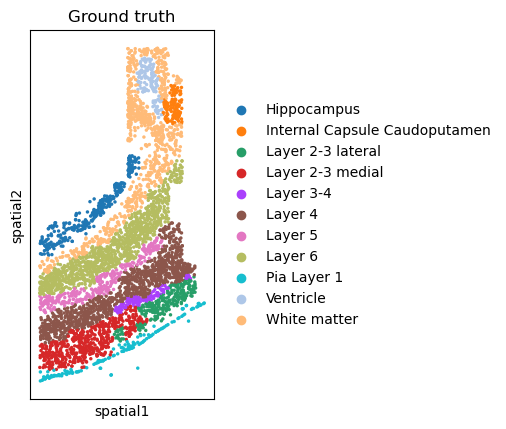

In [18]:
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["Region"],
    title=["Ground truth"],
    spot_size=500,
    show=True
)

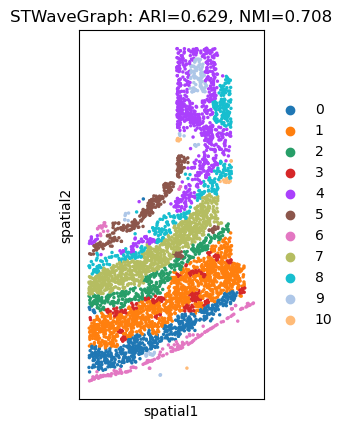

In [20]:

sc.pl.spatial(
    adata,
    img_key="hires",
    color=["pred_domain"],
    title=[f"STWaveGraph: ARI={ARI:.3f}, NMI={NMI:.3f}"],
    spot_size=500,
    show=True
)
